In [1183]:
# logistical/os/plotting packages
import time
import os
from copy import deepcopy
# from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# mathematics packages
from random import sample
import random
import numpy as np
# import pandas as pd
# import math
#from scipy.integrate import odeint

# define sources of randomness
#random.seed(42) #not needed but added to compare with other code templates
#rng = np.random.default_rng()

In [ ]:
def count_new_infections(x):
    _, num_patches = x.shape
    total_cases = np.zeros(num_patches)

    for j in range(0,num_patches):
        daily_cases = x[:,j]
        total_cases[j] = daily_cases[0] + np.cumsum(np.maximum(np.diff(daily_cases),0))[-1]

    return np.sum(total_cases)

def split_losses(population, rates, rng):
    conc_rates = np.stack(rates, axis=1)
    total_rate = conc_rates.sum(axis=1)

    losses = np.minimum(rng.poisson(lam=total_rate*population), population)
    probabilities = np.divide(conc_rates, total_rate[..., None])  # reshaping so divide works correctly

    counts = np.zeros((len(population), conc_rates.shape[1]), dtype=int)
    for i, loss in enumerate(losses):
        if loss > 0:
            counts[i,:] = rng.multinomial(int(loss), probabilities[i,:])

    return losses, counts

def step_patches_birth_vax(x, disease_params, conn_mat, num_patches, rng, importations=0):
    # break state up into epidemiologically relevant categories
    #x is all subpopulations
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches]  # importations introduces noise and indicates disease arrival
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma = disease_params
    force_of_infection = beta*np.matmul(conn_mat, c*E+I+importations)/N

    S1_losses, S1_cats = split_losses(S1, (force_of_infection, alpha, noo), rng)
    S1_infections, S1_vaccinations, S1_deaths = S1_cats.T
    S1_births = rng.poisson((1-b)*mu*N)

    S2_losses, S2_cats = split_losses(S2, (force_of_infection, noo), rng)
    S2_infections, S2_deaths = S2_cats.T

    V_losses, V_cats = split_losses(V, (sigma*force_of_infection, omega, noo), rng)
    V_births = S1_births = rng.poisson(b*mu*N)
    V_infections, V_waning, V_deaths = V_cats.T

    E_losses, E_cats = split_losses(E, (gamma, noo), rng)
    E_progressions, E_deaths = E_cats.T

    I_losses, I_cats = split_losses(I, (delta, noo), rng)
    I_progressions, I_deaths = I_cats.T

    R_deaths = np.minimum(rng.poisson(lam=noo*R), R)

    S1_new = S1 + S1_births - S1_losses
    V_new = V + V_births + S1_vaccinations - V_losses
    S2_new = S2 + V_waning - S2_losses
    E_new = E + S1_infections + S2_infections + V_infections - E_losses
    I_new = I + E_progressions - I_losses
    R_new = R + I_progressions - R_deaths

    return np.concat((S1_new, S2_new, V_new, E_new, I_new, R_new))

def calc_R_t(x, disease_params):
    # find patch numbers
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches]  # importations introduces noise and indicates disease arrival
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma = disease_params
    S_1_star = S1/N
    V_star = V/N
    S_2_star = S2/N
    frac_adjusted = S_1_star + S_2_star + sigma*V_star
    return (beta*frac_adjusted*(c*(noo+delta)+gamma)/((noo+gamma)*(noo+delta)))

def wastewater_detection(x, active_patches, inclusion_fracs, exposure_sensitivity, rng, importations=0):
    num_patches = len(active_patches)
    
    S1=x[0:num_patches][active_patches]
    S2=x[num_patches:2*num_patches][active_patches]
    V=x[2*num_patches:3*num_patches][active_patches]
    E=x[3*num_patches:4*num_patches][active_patches]
    I=x[4*num_patches:5*num_patches][active_patches] + importations[active_patches]  # importations adds noise and jump-starts outbreaks
    R=x[5*num_patches:6*num_patches][active_patches]
    N=S1+S2+V+E+I+R

    cat_fracs = np.stack(((S1+S2+V+R)/N,E/N,I/N), axis=1)
    total_sampled = np.rint(inclusion_fracs*N)
    sampled_proportions = np.zeros((len(N), 3))
    for i,total_included in enumerate(total_sampled):
        sampled_proportions[i,:] = rng.multinomial(total_included, cat_fracs[i,:])/total_included

    fraction_shedding = (exposure_sensitivity*sampled_proportions[:,1]+sampled_proportions[:,2])
    # expand results to all patches
    all_patches_shedding = np.zeros(num_patches)
    all_patches_shedding[active_patches] = fraction_shedding

    return all_patches_shedding

def clinical_surveillance(x, active_patches, healthcare_prob, background_rash_rate, test_sens_spec, rng, importations=0):
    num_patches = len(active_patches)
    
    S1=x[0:num_patches][active_patches]
    S2=x[num_patches:2*num_patches][active_patches]
    V=x[2*num_patches:3*num_patches][active_patches]
    E=x[3*num_patches:4*num_patches][active_patches]
    I=x[4*num_patches:5*num_patches][active_patches] + importations[active_patches]  # importations adds noise and jump-starts outbreaks
    R=x[5*num_patches:6*num_patches][active_patches]
    N=S1+S2+V+E+I+R

    background_febrile_rash_cases = rng.poisson(lam=N*background_rash_rate)
    test_true_pos, test_true_neg = test_sens_spec

    total_rash = background_febrile_rash_cases+I
    cat_totals = np.stack((I, background_febrile_rash_cases), axis=1).astype(int)
    total_sampled = np.rint(healthcare_prob*total_rash).astype(int)
    sampled_measles = np.zeros(len(N))
    for i,total_included in enumerate(total_sampled):
        included_cases = rng.multivariate_hypergeometric(cat_totals[i,:], total_included)
        sampled_measles[i] = included_cases[0]*test_true_pos + included_cases[1]*(1-test_true_neg)

    # expand results to all patches
    all_patches_shedding = np.zeros(num_patches)
    all_patches_shedding[active_patches] = sampled_measles/N  # return as a percentage of population
    return all_patches_shedding

def generate_pre_importations(num_days, num_patches, importation_rate, importation_departure):
    gen_rng = np.random.default_rng()
    importation_history = np.zeros((num_days, num_patches))
    for i in range(1,num_days):
            importation_history[i,:] = gen_rng.poisson(lam=importation_rate) + np.rint(0, importation_history[i-1,:]-gen_rng.poisson(lam=importation_history[i-1,:]*importation_departure))

    return importation_history

def simulate_system(num_days, num_patches, static_disease_params, seasonal_pars, n_people, sia_alpha,
                    importation_rate, importation_departure, conn_mat, clusters,
                    clinical_surveillance_pars, wastewater_surveillance_pars,
                    given_seed=None, preloaded_importations=None):
    
    use_preloaded_importations = preloaded_importations is not None
    
    # can fix randomness for reproducibility
    if given_seed is None:
        given_seed = np.random.randint(0,high=10**9)
    rng = np.random.default_rng(seed=given_seed)
    
    # to hold results of simulation
    results = np.zeros((num_days, num_patches*6))

    # unpacks disease params for later use
    alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma = static_disease_params
    disease_params = deepcopy(static_disease_params)
    trans_period, trans_start_day, trans_variation = seasonal_pars
    adjusted_alpha = deepcopy(alpha)

    # initialize simulation state
    S_1_star = (1-b)*mu/(alpha+noo)
    V_star = (b*mu+alpha*S_1_star)/(omega+noo)
    S_2_star = omega/noo*V_star

    # unpack clinical surveillance parameters
    clin_floor, clin_cons_days, clin_cum_floor, healthcare_prob, test_sens_spec, background_rash_rate = clinical_surveillance_pars

    # unpack wastewater surveillance parameters
    waste_sampling_frequency, waste_sample_delay, waste_threshold, active_wastewater_sites, inclusion_fracs, exposure_sensitivity = wastewater_surveillance_pars

    ic = np.zeros(num_patches*6)
    ic[0:num_patches] = np.rint(n_people*S_1_star)
    ic[num_patches:2*num_patches] = np.rint(n_people*S_2_star)
    ic[2*num_patches:3*num_patches] = np.rint(n_people*V_star)
    results[0,:] = ic

    # hold R_t history
    r_t_vals = np.zeros((num_days, num_patches))
    r_t_vals[0,:] = calc_R_t(ic, disease_params)
    r_t_no_sia = np.zeros((num_days, num_patches))
    r_t_vals[0,:] = calc_R_t(ic, disease_params)
    vax_hist = np.zeros((num_days, num_patches))
    vax_hist[0,:] = alpha

    # hold surveillance system outputs
    empirical_shedding = np.zeros((num_days, num_patches))
    empirical_clinical = np.zeros((num_days, num_patches))

    trigger_clinical = np.array([[False for _ in range(0, num_patches)] for _ in range(0,num_days)])
    clinical_active = np.zeros(num_patches)
    clinical_detections = np.array([False for _ in range(0,num_patches)])

    importations = np.zeros(num_patches)  # this will hold temporary cases that introduce noise into the system and jump-start outbreaks
    if use_preloaded_importations:
        importation_history = deepcopy(preloaded_importations)
    else:
        importation_history = np.zeros((num_days, num_patches))

    for i in range(1,num_days):
        adjusted_alpha[clinical_detections] = sia_alpha
        seasonal_beta = beta*((1-trans_variation)+trans_variation*(np.sin(np.pi*(i+trans_start_day)/trans_period)))
        disease_params[0] = adjusted_alpha # activate sia in all patches where clinical surveillance has confirmed measles
        disease_params[1] = seasonal_beta  # replace beta with seasonal version
        if use_preloaded_importations:
            importations = importation_history[i,:]
        else:
            importations = np.rint(0, importations-rng.poisson(lam=importations*importation_departure))
            importations += rng.poisson(lam=importation_rate)
            importation_history[i,:] = deepcopy(importations)

        results[i,:] = step_patches_birth_vax(results[i-1,:], disease_params, conn_mat, num_patches, rng, importations=importations)
        r_t_vals[i,:] = calc_R_t(results[i,:], disease_params)
        r_t_no_sia[i,:] = calc_R_t(results[i,:], static_disease_params)
        vax_hist[i,:] = deepcopy(adjusted_alpha)
        empirical_clinical[i,:] = clinical_surveillance(results[i,:], clinical_active.astype(bool), healthcare_prob, background_rash_rate, test_sens_spec, rng, importations=importations)

        # apply wastewater sampling, will trigger clinical follow-up after appropriate delay
        if i % waste_sampling_frequency == 0:
            empirical_shedding[i,:] = wastewater_detection(results[i,:], active_wastewater_sites, inclusion_fracs, exposure_sensitivity, rng, importations=importations)
            trigger_clinical[min(i+waste_sample_delay, num_days-1),:] = (empirical_shedding[i,:] >= waste_threshold).astype(float)
        
        # more efficient to do Boolean checks via matrix logic
        clinical_active += np.matmul(clusters, trigger_clinical[i,:]+clinical_detections.astype(float))
        active = clinical_active.astype(bool)
        if np.any(active):
            start = max(i-clin_cons_days+1,0)
            window = empirical_clinical[start:i+1,:]
            active_window = window[:,active]
            clinical_detections[active] = (np.all(active_window >= clin_floor, axis=0) & (np.sum(active_window, axis=0) >= clin_cum_floor))

    return results, importation_history, r_t_vals, vax_hist, r_t_no_sia

In [1185]:
num_patches = 50
num_days = 500
alpha = 0.0*np.ones(num_patches)
adjusted_alpha = deepcopy(alpha)
sia_alpha = 0.005
beta = 2.12*np.ones(num_patches)
b=0.71*np.ones(num_patches)  # Cameroon
gamma = 0.1*np.ones(num_patches)
delta = 0.125*np.ones(num_patches)
c = 0*np.ones(num_patches)
mu = 0.00007397*np.ones(num_patches)
noo = 0.00007397*np.ones(num_patches)  # if noo is not equal to mu, then this R_0 is incorrect. Just for diagnostic purposes
omega = 0.0*np.ones(num_patches)
sigma = 0.0*np.ones(num_patches)
n_people = 3000*np.ones(num_patches)
background_rash_rate = 0.005

# seasonal variation measles
period = 365
start_day = 0
variation = 0.2
seasonal_pars = [period, start_day, variation]

In [1186]:
S_1_star = (1-b)*mu/(alpha+noo)
V_star = (b*mu+alpha*S_1_star)/(omega+noo)
S_2_star = omega/noo*V_star
frac_adjusted = S_1_star + S_2_star + sigma*V_star
S_1_sia = (1-b)*mu/(sia_alpha+noo)
V_sia = (b*mu+alpha*S_1_sia)/(omega+noo)
S_2_sia = omega/noo*V_sia
frac_sia = S_1_sia + S_2_sia + sigma*V_sia
R_0 = (beta*frac_adjusted*(c*(noo+delta)+gamma)/((noo+gamma)*(noo+delta)))[0]
R_0_sia = (beta*frac_sia*(c*(noo+delta)+gamma)/((noo+gamma)*(noo+delta)))[0]
print(f"Fixed population R_0: {R_0:.3f}")
print(f"SIA R_0: {R_0_sia:.3f}")
print(f"S1: {(S_1_star*n_people)[0]} S2: {(S_2_star*n_people)[0]} V: {(V_star*n_people)[0]}")

# importations = np.zeros(num_patches)  # this will hold temporary cases that introduce noise into the system and jump-start outbreaks
importation_rate = 0.01*np.ones(num_patches)  # a daily importation rate
# importation_rate = np.zeros(num_patches)
# start_patch = 5
# importation_rate[start_patch] = 0.01
# importation_rate = 1.06*mu*R_0/np.sqrt(n_people)
importation_departure = 0.1*np.ones(num_patches)
# importation_history = np.zeros((num_days, num_patches))

disease_params_static = [alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma]
# disease_params = deepcopy(disease_params_static)
# ic = np.zeros(num_patches*6)
# ic[0:num_patches] = np.rint(n_people*S_1_star)
# ic[num_patches:2*num_patches] = np.rint(n_people*S_2_star)
# ic[2*num_patches:3*num_patches] = np.rint(n_people*V_star)

Fixed population R_0: 4.912
SIA R_0: 0.072
S1: 870.0000000000001 S2: 0.0 V: 2130.0


In [1187]:
# surveillance accuracy characteristics
inclusion_fracs = 0.9
exposure_sensitivity = 1
healthcare_prob = 0.2
test_sens_spec = [1,1]

# wastewater surveillance thresholds
waste_sampling_frequency = 7
sample_delay = 3
waste_threshold = 0.001/3
active_wastewater_sites = np.array([False for _ in range(0,num_patches)])
active_wastewater_sites[0:4] = True

# clinical surveillance thresholds
clin_floor = 0.001/3
clin_cons_days = 5
clin_cum_floor = 0
# clin_delay = 0

Text(0.5, 1.0, 'Adjacency matrix for subpopulations')

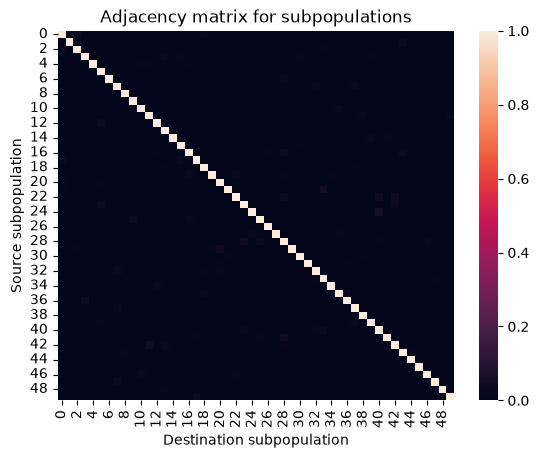

In [1188]:
mat_rng = np.random.default_rng()
conn_mat = np.eye(num_patches)
clusters = np.eye(num_patches)
for source in range(0, num_patches):
    for k in range(0,5):
        destination = np.random.randint(0, num_patches)
        if source != destination:
            conn_mat[source,destination] = mat_rng.beta(1,99)
            clusters[destination,source] = 1

clusters /= num_days
ax = plt.axes()
sns.heatmap(conn_mat, ax=ax)
ax.set_xlabel("Destination subpopulation")
ax.set_ylabel("Source subpopulation")
ax.set_title("Adjacency matrix for subpopulations")

In [1189]:
clinical_surveillance_pars = [clin_floor, clin_cons_days, clin_cum_floor, healthcare_prob, test_sens_spec, background_rash_rate]
wastewater_surveillance_pars = [waste_sampling_frequency, sample_delay, waste_threshold, active_wastewater_sites, inclusion_fracs, exposure_sensitivity]
difference_in_cases = 0
sample_runs = 1
some_key = np.random.randint(0,high=10**7)

for sample_num in range(0, sample_runs):
    pre_imp_hist = generate_pre_importations(num_days, num_patches, importation_rate, importation_departure)
    #pre_imp_hist = None
    
    results,importation_history,r_t,vax_hist,r_t_no_sia=simulate_system(num_days, num_patches, disease_params_static, seasonal_pars, n_people, sia_alpha,
                    importation_rate, importation_departure, conn_mat, clusters,
                    clinical_surveillance_pars, wastewater_surveillance_pars, preloaded_importations=pre_imp_hist)

    results_no_sia,no_sia_imp_hist,r_t_absent_sia,vax_hist_no_sia,_=simulate_system(num_days, num_patches, disease_params_static, seasonal_pars, n_people, 0,
                    importation_rate, importation_departure, conn_mat, clusters,
                    clinical_surveillance_pars, wastewater_surveillance_pars, preloaded_importations=pre_imp_hist)

    difference_in_cases += np.sum(results_no_sia[:,4*num_patches:5*num_patches]) - np.sum(results[:,4*num_patches:5*num_patches])

count_new_infections(results_no_sia[:,4*num_patches:5*num_patches])
print(difference_in_cases/sample_runs)

# results,importation_history,r_t,vax_hist,r_t_no_sia=simulate_system(num_days, num_patches, disease_params_static, seasonal_pars, n_people, sia_alpha,
#                 importation_rate, importation_departure, conn_mat, clusters,
#                 clinical_surveillance_pars, wastewater_surveillance_pars)

# results_no_sia,no_sia_imp_hist,_,_,_=simulate_system(num_days, num_patches, disease_params_static, seasonal_pars, n_people, 0,
#                 importation_rate, importation_departure, conn_mat, clusters,
#                 clinical_surveillance_pars, wastewater_surveillance_pars)

28117.0


Text(0, 0.5, 'Infections')

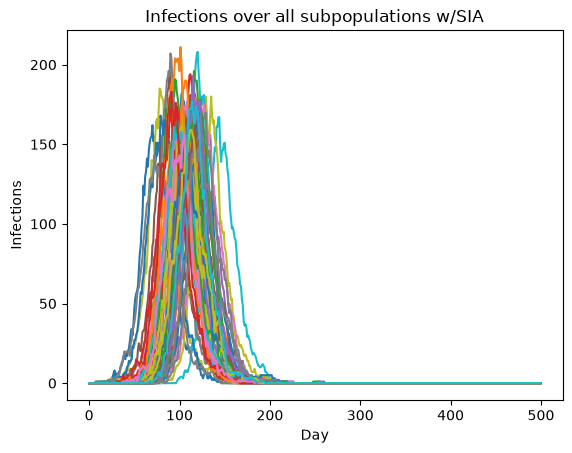

In [1190]:
for j in range(0,num_patches):
    plt.plot(list(range(0,num_days)), results[:,j+4*num_patches])
plt.title("Infections over all subpopulations w/SIA")
plt.xlabel("Day")
plt.ylabel("Infections")
#plt.ylim([0, 10])
#plt.xlim([75,150])

Text(0, 0.5, 'Infections')

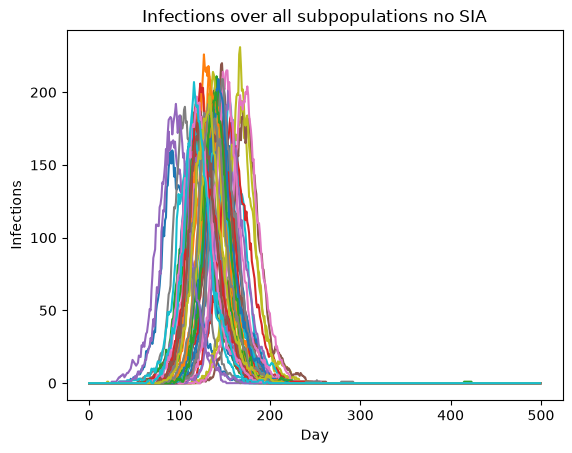

In [1191]:
for j in range(0,num_patches):
    plt.plot(list(range(0,num_days)), results_no_sia[:,j+4*num_patches])
plt.title("Infections over all subpopulations no SIA")
plt.xlabel("Day")
plt.ylabel("Infections")
#plt.ylim([0, 10])
#plt.xlim([75,150])

Text(0, 0.5, '#')

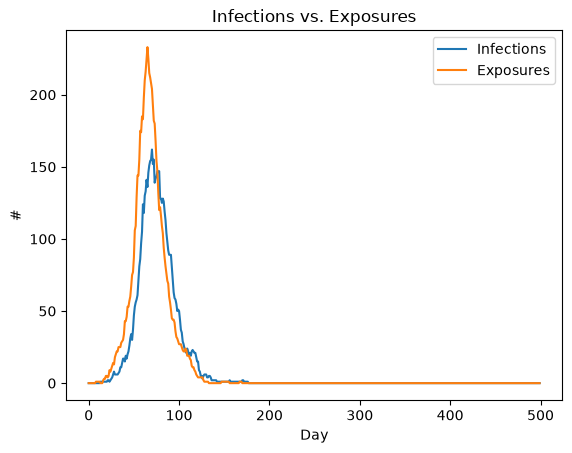

In [1192]:
demo_patch=0
plt.plot(list(range(0,num_days)), results[:,demo_patch+4*num_patches], label="Infections")
plt.plot(list(range(0,num_days)), results[:,demo_patch+3*num_patches], label="Exposures")
plt.legend()
plt.title("Infections vs. Exposures")
plt.xlabel("Day")
plt.ylabel("#")
#plt.ylim([0, 10])
#plt.xlim([75,150])

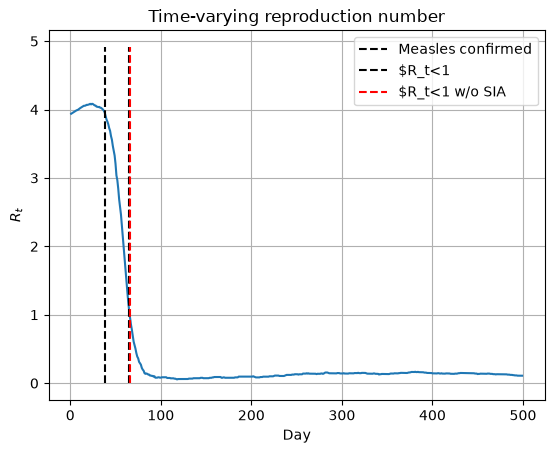

In [1193]:
campaign_begins = np.flatnonzero(vax_hist[:,demo_patch])[0]
doom_date = np.flatnonzero(r_t[1:,demo_patch] < 1)[0]
doom_no_sia = np.flatnonzero(r_t_no_sia[1:,demo_patch] < 1)[0]
plt.plot(list(range(1,num_days)),r_t[1:,demo_patch])
plt.vlines(campaign_begins, 0, r_t[0,demo_patch],linestyles="dashed", colors="black", label="Measles confirmed")
plt.vlines(doom_date, 0, r_t[0,demo_patch],linestyles="dashed", colors="black", label=r"$R_t<1")
plt.vlines(doom_no_sia, 0, r_t[0,demo_patch],linestyles="dashed", colors="red", label=r"$R_t<1 w/o SIA")
plt.title("Time-varying reproduction number")
plt.ylabel(r"$R_t$")
plt.xlabel("Day")
plt.legend()
plt.grid()

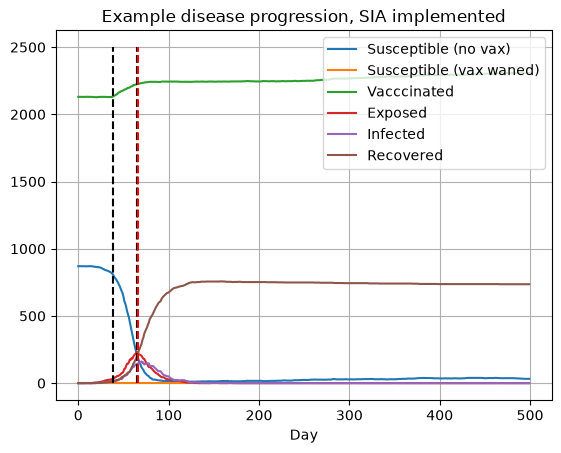

In [1194]:
syms = ["S1", "S2", "V", "E", "I", "R"]
sym_names = ["Susceptible (no vax)", "Susceptible (vax waned)", "Vacccinated", "Exposed", "Infected", "Recovered"]
for k in range(0,6):
    y_vals = results[:,demo_patch+k*num_patches]
    if syms[k] == "I":
        y_vals += importation_history[:,12]
    plt.plot(list(range(0,num_days)), y_vals, label=sym_names[k])
plt.vlines(campaign_begins,0,2500,linestyles="dashed",colors="black")
plt.vlines(doom_date, 0, 2500, linestyles="dashed",colors="black")
plt.vlines(doom_no_sia, 0, 2500, linestyles="dashed",colors="red")
plt.legend(loc="upper right")
plt.title("Example disease progression, SIA implemented")
plt.xlabel("Day")
plt.grid()
# plt.ylim([0,5])
# plt.xlim([0,10])
plt.show()

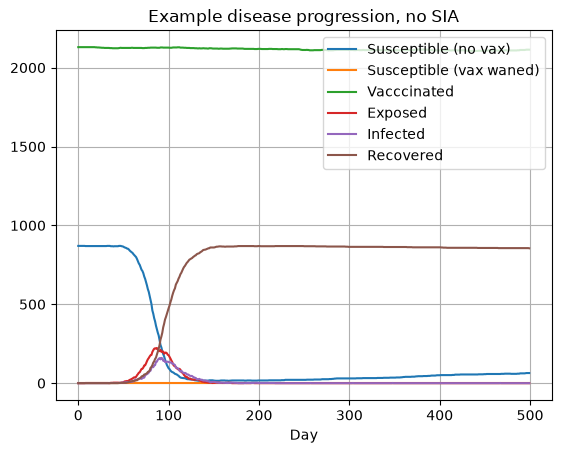

In [1195]:
#campaign_no_begin = np.flatnonzero(vax_hist_no_sia[:,demo_patch])[0]
#doom_date_no_sia = np.flatnonzero(r_t_absent_sia[1:,demo_patch] < 1)[0]
for k in range(0,6):
    y_vals = results_no_sia[:,demo_patch+k*num_patches]
    if syms[k] == "I":
        y_vals += no_sia_imp_hist[:,12]
    plt.plot(list(range(0,num_days)), y_vals, label=sym_names[k])
#plt.vlines(campaign_no_begin,0,2500,linestyles="dashed",colors="black")
#plt.vlines(doom_date, 0, 2500, linestyles="dashed",colors="black")
plt.legend(loc="upper right")
plt.title("Example disease progression, no SIA")
plt.xlabel("Day")
plt.grid()
plt.show()

In [1196]:
# def find_outbreak_day(example_series, incident_floor, cons_days, cumulative_floor):
#     alerts = []
#     cumulative_example = np.cumsum(example_series)
#     for j in range(0,len(example_series)):
#         alerts.append(np.all(example_series[max(j+1-cons_days,0):j+1]>=incident_floor) and cumulative_example[j]>=cumulative_floor)

#     true_indices = np.flatnonzero(alerts)
#     outbreak_index = true_indices[0] if true_indices.size else len(example_series)
#     return outbreak_index

# def find_clinical(example_series, clin_floor, clin_cum_floor):
#     cumulative_example = np.sum(example_series)
#     return np.all(example_series>=clin_floor) and cumulative_example>=clin_cum_floor